In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV Version:", cv2.__version__)
print("NumPy Version :", np.__version__)

Matplotlib is building the font cache; this may take a moment.


OpenCV Version: 5.0.0
NumPy Version : 2.5.1


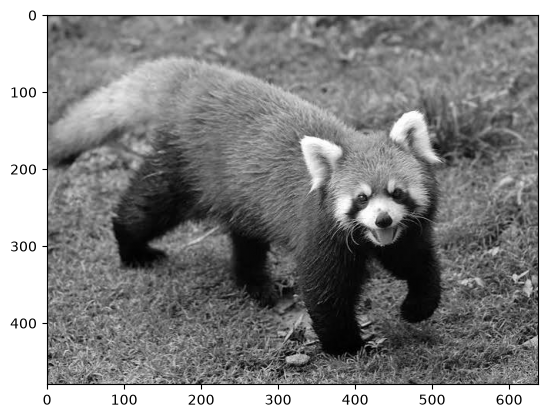

In [2]:
image = cv2.imread('images.jpeg' , cv2.IMREAD_GRAYSCALE)
plt.imshow(image, cmap='gray')
plt.show()

In [3]:
def add_salt_and_pepper_noise(image, probability):
    noisy = image.copy()

    random = np.random.rand(*image.shape)

    noisy[random < (probability / 2)] = 0  # Pepper noise
    noisy[random > 1 - (probability / 2)] = 255  # Salt noise

    return noisy

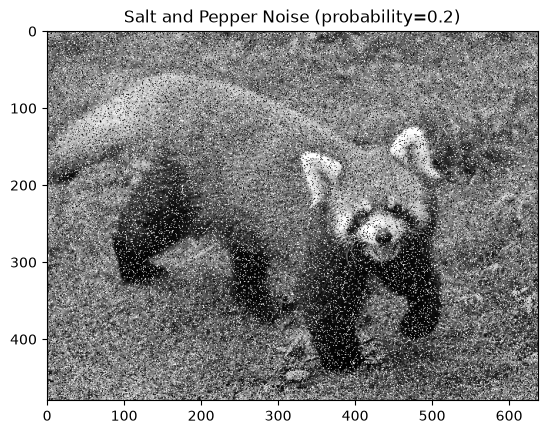

In [14]:
prob = 0.2

noisy = add_salt_and_pepper_noise(image, prob)
plt.imshow(noisy, cmap='gray')
plt.title(f'Salt and Pepper Noise (probability={prob})')
plt.show()

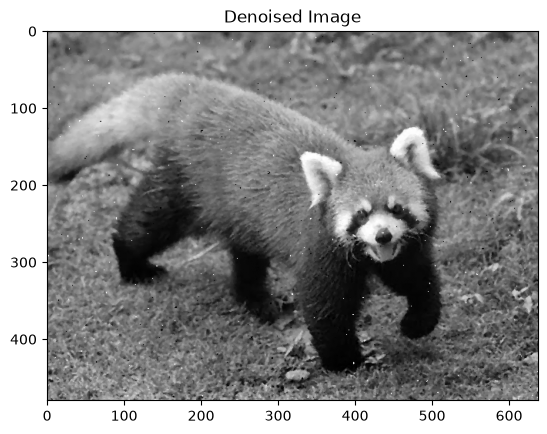

In [36]:
def remove_salt_and_pepper_noise(image, kernel_size):
    denoised = cv2.medianBlur(image, kernel_size)
    return denoised

denoised = remove_salt_and_pepper_noise(noisy, 3)
plt.imshow(denoised, cmap='gray')
plt.title('Denoised Image')
plt.show()

In [4]:
#MOVING WINDOW FILTERING

import numpy as np
from PIL import Image
from numpy.lib.stride_tricks import sliding_window_view

# 1. Load image and convert to grayscale
img = Image.open('images.jpeg').convert('L')
arr = np.array(img, dtype=np.float32)

# 2. Sobel kernels (detect horizontal and vertical edges)
sobel_x = np.array([[-1, 0, 1],
                     [-2, 0, 2],
                     [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                     [ 0,  0,  0],
                     [ 1,  2,  1]])

# 3. Slide a 3x3 window over every pixel
windows = sliding_window_view(arr, (3, 3))  # shape: (H-2, W-2, 3, 3)

# 4. Apply filter at each window position (element-wise multiply + sum)
grad_x = np.einsum('ijkl,kl->ij', windows, sobel_x)
grad_y = np.einsum('ijkl,kl->ij', windows, sobel_y)

# 5. Combine into edge magnitude
edges = np.sqrt(grad_x**2 + grad_y**2)

# 6. Normalize to 0-255 and save
edges = (edges / edges.max() * 255).astype(np.uint8)
Image.fromarray(edges).save('edges_output.jpg')

print("Done! Saved as edges_output.jpg")


Done! Saved as edges_output.jpg
